<a href="https://colab.research.google.com/github/AlessiaSerra/Clickbait-Detection/blob/main/ClickBaitDetection_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
pip install datasets pandas scikit-learn numpy

--> Caricamento del dataset da Hugging Face...
--> Estrazione feature AIT sul Train Set (3500 istanze)...
--> Estrazione feature AIT sul Test Set (1500 istanze)...

EXPLORATORY DATA ANALYSIS: UNEXPECTEDNESS vs CLICKBAIT
            C_d                        C_w                         U                      U_norm                    
           mean        std median     mean       std median     mean        std median      mean       std    median
label                                                                                                               
0      108.8416  14.897452  108.0  19.9472  6.015886   20.0 -88.8944  10.743622  -88.0 -1.838861  0.447098 -1.769230
1      114.2592  16.168085  112.0  27.4928  7.614062   28.0 -86.7664   9.778736  -88.0 -1.626623  0.388290 -1.543859

Pearson Correlation (U, Label):  0.1030 (p-value: 2.7908e-13)
Spearman Correlation (U, Label): 0.0868 (p-value: 7.8945e-10)
Two-sample t-test su U: t = 7.3240, p-value = 2.7908e-13


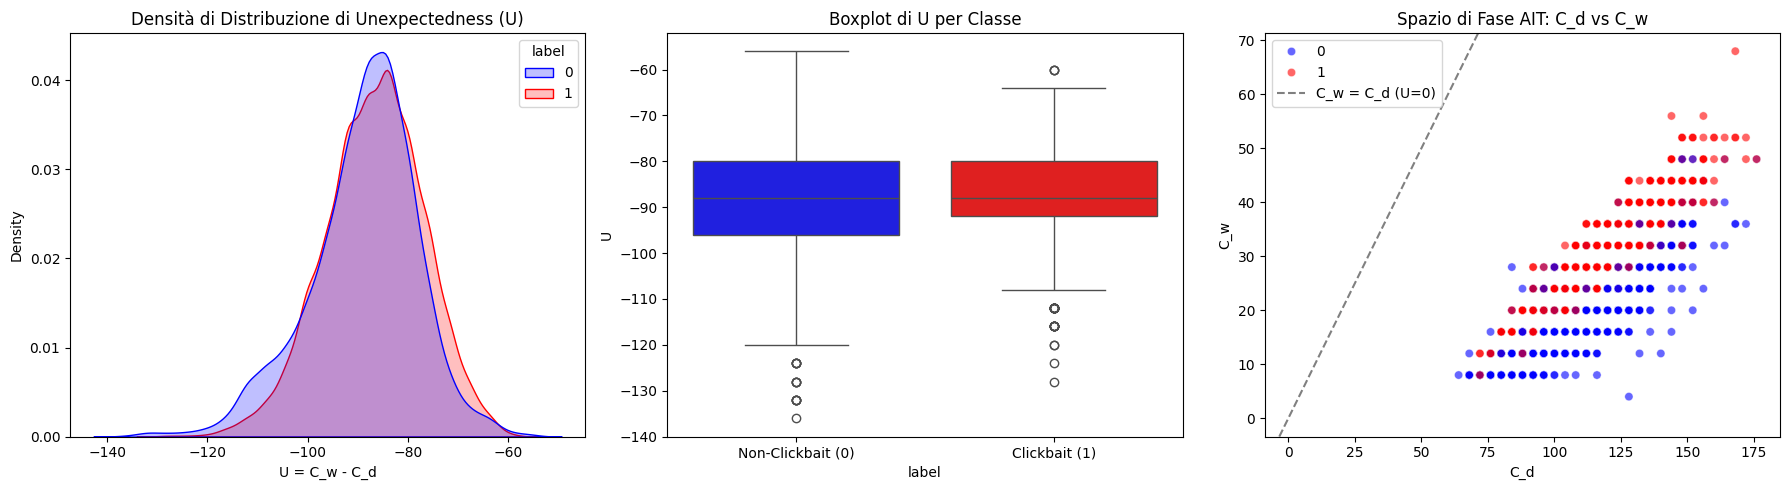


BENCHMARK COMPARATIVO SUL TEST SET
                       Modello  Accuracy  F1-Score  ROC-AUC
  AIT Detector (Random Forest)    0.8073    0.8141   0.8073
   Random Classifier (Uniform)    0.4887    0.4876   0.4887
Random Classifier (Stratified)    0.4953    0.4923   0.4953
  Logistic Regression (TF-IDF)    0.8867    0.8831   0.8867
   HYBRID Model (TF-IDF + AIT)    0.8987    0.8960   0.8987

Report Dettagliato Classificatore AIT (Random Forest):
              precision    recall  f1-score   support

  Legitimate       0.83      0.77      0.80       750
   Clickbait       0.79      0.84      0.81       750

    accuracy                           0.81      1500
   macro avg       0.81      0.81      0.81      1500
weighted avg       0.81      0.81      0.81      1500



In [23]:
import lzma
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score, accuracy_score, f1_score
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from scipy.sparse import hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# =====================================================================
# 1. CLASSE DI CALCOLO COMPLESSITÀ ED UNEXPECTEDNESS (AIT)
# =====================================================================
class AITComplexityEngine:
    def __init__(self, background_corpus: str):
        """
        Inizializza il motore AIT con un corpus di background (World Knowledge).
        """
        self.world_knowledge = background_corpus.encode('utf-8')
        # Pre-compressione del background per calcolare C_w marginale
        self.compressed_world_size = len(lzma.compress(self.world_knowledge))

    def get_cd(self, text: str) -> int:
        """
        Complessità descrittiva C_d: Z(text)
        """
        return len(lzma.compress(text.encode('utf-8')))

    def get_cw(self, text: str) -> int:
        """
        Complessità causale approssimata C_w: Z(World + text) - Z(World)
        """
        combined = self.world_knowledge + b" " + text.encode('utf-8')
        return max(len(lzma.compress(combined)) - self.compressed_world_size, 0)

    def compute_metrics(self, text: str) -> tuple:
        cd = self.get_cd(text)
        cw = self.get_cw(text)
        u = cw - cd
        # Unexpectedness normalizzata sulla lunghezza (evita bias di string length)
        u_norm = u / (len(text) + 1e-5)
        return cd, cw, u, u_norm


# =====================================================================
# 2. CARICAMENTO E PREPARAZIONE DEL DATASET
# =====================================================================
print("--> Caricamento del dataset da Hugging Face...")
raw_dataset = load_dataset("christinacdl/clickbait_detection_dataset", split="train")
df_raw = pd.DataFrame(raw_dataset)

# Riconoscimento automatico delle colonne per testo e target
text_col = 'text' if 'text' in df_raw.columns else ('headline' if 'headline' in df_raw.columns else df_raw.columns[0])
label_col = 'label' if 'label' in df_raw.columns else df_raw.columns[1]

# 1. Estrai un World Knowledge massiccio e indipendente (5000 testi legittimi)
df_background = df_raw[df_raw[label_col] == 0].head(5000)
world_reference_text = " ".join(df_background[text_col].tolist())
engine = AITComplexityEngine(background_corpus=world_reference_text)

# 2. Rimuovi questi testi dal dataset raw per evitare sovrapposizioni e data leakage
df_remaining = df_raw.drop(df_background.index)

# 3. Campiona i 1000 record per l'esperimento dai dati rimanenti
SAMPLE_SIZE = 5000
df_cb = df_remaining[df_remaining[label_col] == 1].sample(SAMPLE_SIZE // 2, random_state=42)
df_non_cb = df_remaining[df_remaining[label_col] == 0].sample(SAMPLE_SIZE // 2, random_state=42)
df = pd.concat([df_cb, df_non_cb]).sample(frac=1.0, random_state=42).reset_index(drop=True)

# 4. Esegui il Train/Test split
train_df, test_df = train_test_split(df, test_size=0.3, random_state=42, stratify=df[label_col])

# Funzione per estrarre le metriche AIT
def extract_ait_features(dataset):
    cd_list, cw_list, u_list, unorm_list = [], [], [], []
    for text in dataset[text_col]:
        cd, cw, u, u_norm = engine.compute_metrics(str(text))
        cd_list.append(cd)
        cw_list.append(cw)
        u_list.append(u)
        unorm_list.append(u_norm)

    dataset = dataset.copy()
    dataset['C_d'] = cd_list
    dataset['C_w'] = cw_list
    dataset['U'] = u_list
    dataset['U_norm'] = unorm_list
    return dataset

print(f"--> Estrazione feature AIT sul Train Set ({len(train_df)} istanze)...")
train_df = extract_ait_features(train_df)

print(f"--> Estrazione feature AIT sul Test Set ({len(test_df)} istanze)...")
test_df = extract_ait_features(test_df)

# Riuniamo temporaneamente il dataframe per le grafiche EDA (Sezione 3)
df_eda = pd.concat([train_df, test_df]).reset_index(drop=True)


# =====================================================================
# 3. REQUISITO 1: EXPLORATORY DATA ANALYSIS (CORRELAZIONE E TEST)
# =====================================================================
print("\n" + "="*50)
print("EXPLORATORY DATA ANALYSIS: UNEXPECTEDNESS vs CLICKBAIT")
print("="*50)

# Statistiche per classe
summary = df_eda.groupby(label_col)[['C_d', 'C_w', 'U', 'U_norm']].agg(['mean', 'std', 'median'])
print(summary.to_string())

# Correlazioni
corr_pearson, p_pearson = stats.pearsonr(df_eda['U'], df_eda[label_col])
corr_spearman, p_spearman = stats.spearmanr(df_eda['U'], df_eda[label_col])
t_stat, t_pval = stats.ttest_ind(df_eda[df_eda[label_col] == 1]['U'], df_eda[df_eda[label_col] == 0]['U'])

print(f"\nPearson Correlation (U, Label):  {corr_pearson:.4f} (p-value: {p_pearson:.4e})")
print(f"Spearman Correlation (U, Label): {corr_spearman:.4f} (p-value: {p_spearman:.4e})")
print(f"Two-sample t-test su U: t = {t_stat:.4f}, p-value = {t_pval:.4e}")

# Visualizzazioni grafiche
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
safe_palette = {0: 'blue', 1: 'red', '0': 'blue', '1': 'red'}

# Plot 1: Distribuzione di U
sns.kdeplot(data=df_eda, x='U', hue=label_col, common_norm=False, fill=True, palette=safe_palette, ax=axes[0])
axes[0].set_title("Densità di Distribuzione di Unexpectedness (U)")
axes[0].set_xlabel("U = C_w - C_d")

# Plot 2: Boxplot U
sns.boxplot(data=df_eda, x=label_col, y='U', hue=label_col, palette=safe_palette, legend=False, ax=axes[1])
axes[1].set_xticks([0, 1])  # Risolve il warning sui ticklabels
axes[1].set_xticklabels(["Non-Clickbait (0)", "Clickbait (1)"])
axes[1].set_title("Boxplot di U per Classe")

# Plot 3: Spazio C_d vs C_w
sns.scatterplot(data=df_eda, x='C_d', y='C_w', hue=label_col, alpha=0.6, palette=safe_palette, ax=axes[2])
axes[2].axline((0, 0), slope=1, color='gray', linestyle='--', label='C_w = C_d (U=0)')
axes[2].set_title("Spazio di Fase AIT: C_d vs C_w")
axes[2].legend()

plt.tight_layout()
plt.show()


# =====================================================================
# 4. REQUISITO 2: DETECTOR AIT MULTIVARIATO (RANDOM FOREST)
# =====================================================================
ait_features = ['C_d', 'C_w', 'U', 'U_norm']
X_train_ait = train_df[ait_features]
X_test_ait = test_df[ait_features]
y_train = train_df[label_col]
y_test = test_df[label_col]

# Modello basato solo su metriche di complessità
rf_ait = RandomForestClassifier(n_estimators=200, random_state=42, class_weight='balanced')
rf_ait.fit(X_train_ait, y_train)
test_preds_ait = rf_ait.predict(X_test_ait)


# =====================================================================
# 5. REQUISITO 3: BENCHMARK E MODELLO IBRIDO (AIT + TF-IDF)
# =====================================================================

# 1. Modelli Random
dummy_uniform = DummyClassifier(strategy="uniform", random_state=42)
dummy_uniform.fit(X_train_ait, y_train)
preds_uniform = dummy_uniform.predict(X_test_ait)

dummy_strat = DummyClassifier(strategy="stratified", random_state=42)
dummy_strat.fit(X_train_ait, y_train)
preds_strat = dummy_strat.predict(X_test_ait)

# 2. Modello NLP Tradizionale (TF-IDF + Logistic Regression)
tfidf = TfidfVectorizer(max_features=3000, stop_words='english')
X_train_tfidf = tfidf.fit_transform(train_df[text_col].astype(str))
X_test_tfidf = tfidf.transform(test_df[text_col].astype(str))

lr_model = LogisticRegression(random_state=42, max_iter=1000)
lr_model.fit(X_train_tfidf, y_train)
preds_lr = lr_model.predict(X_test_tfidf)

from sklearn.preprocessing import MaxAbsScaler

# 3. MODELLO IBRIDO CORRETTO (LogReg su feature scalate)
scaler = MaxAbsScaler()
X_train_ait_scaled = scaler.fit_transform(X_train_ait)
X_test_ait_scaled = scaler.transform(X_test_ait)

X_train_hybrid = hstack([X_train_tfidf, X_train_ait_scaled])
X_test_hybrid = hstack([X_test_tfidf, X_test_ait_scaled])

lr_hybrid = LogisticRegression(random_state=42, max_iter=1000)
lr_hybrid.fit(X_train_hybrid, y_train)
preds_hybrid = lr_hybrid.predict(X_test_hybrid)

# Tabella comparativa delle metriche
models = {
    "AIT Detector (Random Forest)": test_preds_ait,
    "Random Classifier (Uniform)": preds_uniform,
    "Random Classifier (Stratified)": preds_strat,
    "Logistic Regression (TF-IDF)": preds_lr,
    "HYBRID Model (TF-IDF + AIT)": preds_hybrid
}

benchmark_records = []
for name, preds in models.items():
    acc = accuracy_score(y_test, preds)
    f1 = f1_score(y_test, preds)
    roc = roc_auc_score(y_test, preds)
    benchmark_records.append({
        "Modello": name,
        "Accuracy": round(acc, 4),
        "F1-Score": round(f1, 4),
        "ROC-AUC": round(roc, 4)
    })

df_benchmark = pd.DataFrame(benchmark_records)

print("\n" + "="*60)
print("BENCHMARK COMPARATIVO SUL TEST SET")
print("="*60)
print(df_benchmark.to_string(index=False))

print("\nReport Dettagliato Classificatore AIT (Random Forest):")
print(classification_report(y_test, test_preds_ait, target_names=["Legitimate", "Clickbait"]))